# taller PyTOUGH - Ejercicio 9
# Modelo de inyección-producción 1D
<img src="model.png" width=600 alt="Figure Description"/>

Ejercicio tomado de <a href="https://github.com/fguemar/tallerPyTOUGH">Taller PyTOUGH</a> por Fernando J. Guerrero, con el uso de biblioteca de funcioes <a href="https://github.com/acroucher/PyTOUGH">PyTOUGH</a> de Adrian Croucher. Uso bajo licencia <a href="https://creativecommons.org/licenses/by-nc-nd/4.0?ref=chooser-v1">Attribution-NonCommercial-NoDerivatives 4.0 International</a>

In [85]:
#==== PyTOUGH ====  
from mulgrids import *
from t2grids import *
from t2data import *
from t2listing import *
#================= 
# calls to system
import os
from vtk import *

#from sympy import *
import math
import numpy as np

import matplotlib.pyplot as plt

cwd=os.getcwd()

In [102]:
# 1D - geometry definition - 1500 m
geo = mulgrid().rectangular([0.3]*5000, [100.0], [100.0], convention=0, chars=ascii_lowercase+ascii_uppercase) 

In [103]:
# Create TOUGH2 Gird from geometry
t2geo=t2grid().fromgeo(geo)

#Define rock type
kref=5. * 9.869233E-16 #  [mD] ---------> [m2]
pomed=rocktype(name = 'pomed', density=2650, porosity=0.01, permeability = [kref, kref, kref], conductivity=2.0, specific_heat = 950) 

# the newly created type rock (and its properties) is added to the object "t2geo" 
t2geo.add_rocktype(pomed)

for blk in t2geo.blocklist:
    blk.rocktype=pomed

#======================================================================
#Definición de archivo de entrada flow.inp -> Objeto de la clase t2data
dat=t2data() 
dat.grid=t2geo 
dat.title='# EOS1 - 1D Injection-production problem'
#------------- EOS1 -------------
dat.multi['num_components']=1
dat.multi['num_equations']=2 
dat.multi['num_phases']=2
dat.multi['num_secondary_parameters']=6

#--------------PARAM-------------
dat.parameter['max_iterations']=8   # NOITE: número máximo de iteraciones de Newton-Raphson (default 8)
dat.parameter['newton_weight']=1.   # WNR: parámetro de iteración de Newton-Raphson (default 1)
#      ...      Output     ...
dat.parameter['print_level']=1              # KDATA: nivel de detalle de salida impresa
dat.parameter['max_timesteps']=9999         # MCYC: numero maximo de pasos de tiempo
dat.parameter['print_interval']=9999        # MCYPR: imprime resultados cada MCYPR pasos de tiempo
#      ---      MOP     ---
dat.parameter['option'][1]=0     # MOP(1-6): Mensajes de salida de subrutinas si es distinto de 0
dat.parameter['option'][5]=1     # MOP(5): Mensajes de funcionamiento de múdulo EOS  
dat.parameter['option'][6]=0     # MOP(6): Mensajes de funcionamiento del Solucionador Lineal
dat.parameter['option'][16]=3    # MOP(16): El paso de tiempo se duplica si NR converge en MOP(16) iteraciones o menos
dat.parameter['option'][21]=3    # MOP(21): Selecciona el solver para el sistema lineal. 3: DSLUCS (default)
#--------------------------
dat.parameter['relative_error']=1.E-5 # RE1: Error relativo usado por Newton Raphson como criterio de convergencia (default 1.E-5)
#      ...    SIM TIME     ...
dat.parameter['tstart']=0.                     # TSTART: Tiempo de inicio de simuación (default 0)
#..........................
#dat.parameter['tstop']=(3600.*24.*365.)*100. # TIMAX: Tiempo de simlación [s]
#..........................
dat.parameter['const_timestep']=1.            # DELTEN: paso de tiempo inicial [s]
#dat.parameter['max_timestep']=(3600.*24.*365.)*10.  # DELTMX: paso de tiempo máximio [s]
dat.parameter['gravity']=9.81                 # GF: Magnitud del campo gravitacional [m/s2]

#================================
#Condiciones iniciales por default - bloque PARAM
dat.start=True 
dat.parameter['default_incons']=[86.0*1.0E5,300.]     #DEP1, DEP2: P,T condiciones de una fase  

#--------------RPCAP-------------
dat.relative_permeability['type']=1                    # Tipo 1. Relación lineal para "Kr"
dat.relative_permeability['parameters']=[0.01,0.,1.,.99]
dat.capillarity['type']=8                             # Tipo 8. Se ignoran efectos capilares. Sin parámetros
dat.capillarity['parameters']=[]
#================================

nyears=30.          # Número de años
yrsec=3600.*24.*365.     # factor de conversión. Seguntos en un año
dat.parameter['tstop']=yrsec*nyears   # TIMAX: Tiempo de simlación [s]

#======================================================================
#        Definicioón de pozos. Dos modalidades de producción: 
#        Por flujo másico ('MASS') o preseión de fondo ('bhp')
rate=4.0 # Flujo másico (kg/s)
pro_bhp=50.0*1.0E5; well_index=8.47E-13 # Pressure (Pa), Productivity index PI [m3] 
# ------WELL 1 ==  Inyector ------------
wll_inj = t2generator(name ='INJ00', block =t2geo.blocklist[0].name, type ='MASS', gx = rate, ex = 500.0E3)

# ------WELL 2 ==  Producer ------------ 
well_type='bhp'  # 'MASS' o 'bhp'

if well_type =='MASS':     
    wll_prd = t2generator(name ='PRO00', block = t2geo.blocklist[-1].name, type ='MASS', gx = -rate)

elif well_type =='bhp': 
    wll_prd = t2generator(name ='PRO00', block = t2geo.blocklist[-1].name, type ='DELV', gx = well_index, ex =pro_bhp) # , hg = espesor
else:
  print("Invalid well condition")

dat.add_generator(wll_inj); 
dat.add_generator(wll_prd)



dat.write('flow.inp')

In [104]:
#===================ATENCIÓN===========================
#  con esta instrucción se ejecuta toughreact en mac
! source /opt/intel/oneapi/setvars.sh; export OMP_NUM_THREADS=1;./treactv413omp_eos1_macos
#===================ATENCIÓN===========================
#  con esta instrucción se ejecuta toughreact en Windows
#! set OMP_NUM_THREADS=1 && treactv360demo_eos3_pc.exe

 
:: initializing oneAPI environment ...
   zsh: ZSH_VERSION = 5.8.1
   args: Using "$@" for setvars.sh arguments: 
:: advisor -- latest
:: compiler -- latest
:: dal -- latest
:: dev-utilities -- latest
:: dnnl -- latest
:: ipp -- latest
:: ippcp -- latest
:: mkl -- latest
:: tbb -- latest
:: vtune_profiler -- latest
:: oneAPI environment initialized ::
 
 
      ----------- TOUGHREACT V4.13omp  -------
                       EOS  1
           Lawrence Berkeley National Laboratory   
                    Jan 10, 2022
 
     ***** OpenMP Parallel Code Settings **** 
    *** maximum number of threads allotted  =   1
    *** maximum number of threads available =  12
 
    --> reading multiphase flow input (flow.inp)
 
    --> performing simulation

    END OF TOUGHREACT V4.13omp  SIMULATION

    ELAPSED TIME =     39.580 SEC   CALCULATION TIME =     39.406 SEC   DATA INPUT TIME =     0.174 SEC



In [105]:
#Análisis de resultados - crea un objeto t2listing a partir del archivo flow.out
lst = t2listing('flow.out')

#posiciónate en la última tabla de la serie de tiempo
lst.last()
#imprime qué tiempo es - ¿correspode con el tiempo de simulación esperado?
print(lst.time/(3600*24*365))

#imprime la tabla de resultados del tiempo en el que 'last'
df=lst.element.DataFrame
df

30.000634195839677


,row,P,T,SG,SW,X1,X2,PCAP,DG,DW
0,a 1,27826100.0,114.418,0.000000,1.000000,1.0,0.0,0.0,0.947949,960.607
1,b 1,27819800.0,114.420,0.000000,1.000000,1.0,0.0,0.0,0.947997,960.603
2,c 1,27813500.0,114.421,0.000000,1.000000,1.0,0.0,0.0,0.948045,960.598
3,d 1,27807300.0,114.423,0.000000,1.000000,1.0,0.0,0.0,0.948093,960.594
4,e 1,27801000.0,114.424,0.000000,1.000000,1.0,0.0,0.0,0.948141,960.590
...,...,...,...,...,...,...,...,...,...,...
4995,aRd 1,5819150.0,273.561,0.302685,0.697315,1.0,0.0,0.0,29.823100,761.748
4996,aRe 1,5815040.0,273.515,0.303174,0.696826,1.0,0.0,0.0,29.800300,761.826
4997,aRf 1,5810920.0,273.469,0.303664,0.696336,1.0,0.0,0.0,29.777500,761.905
4998,aRg 1,5806790.0,273.423,0.304154,0.695846,1.0,0.0,0.0,29.754700,761.983


In [106]:
lst.write_vtk(geo,cwd+'/pView/Results_TOUGH.pvd', grid=t2geo, indices=None, flows=False, wells=True, start_time=0, time_unit='s', flux_matrix=None, blockmap = {}, surface_snap=0.1)

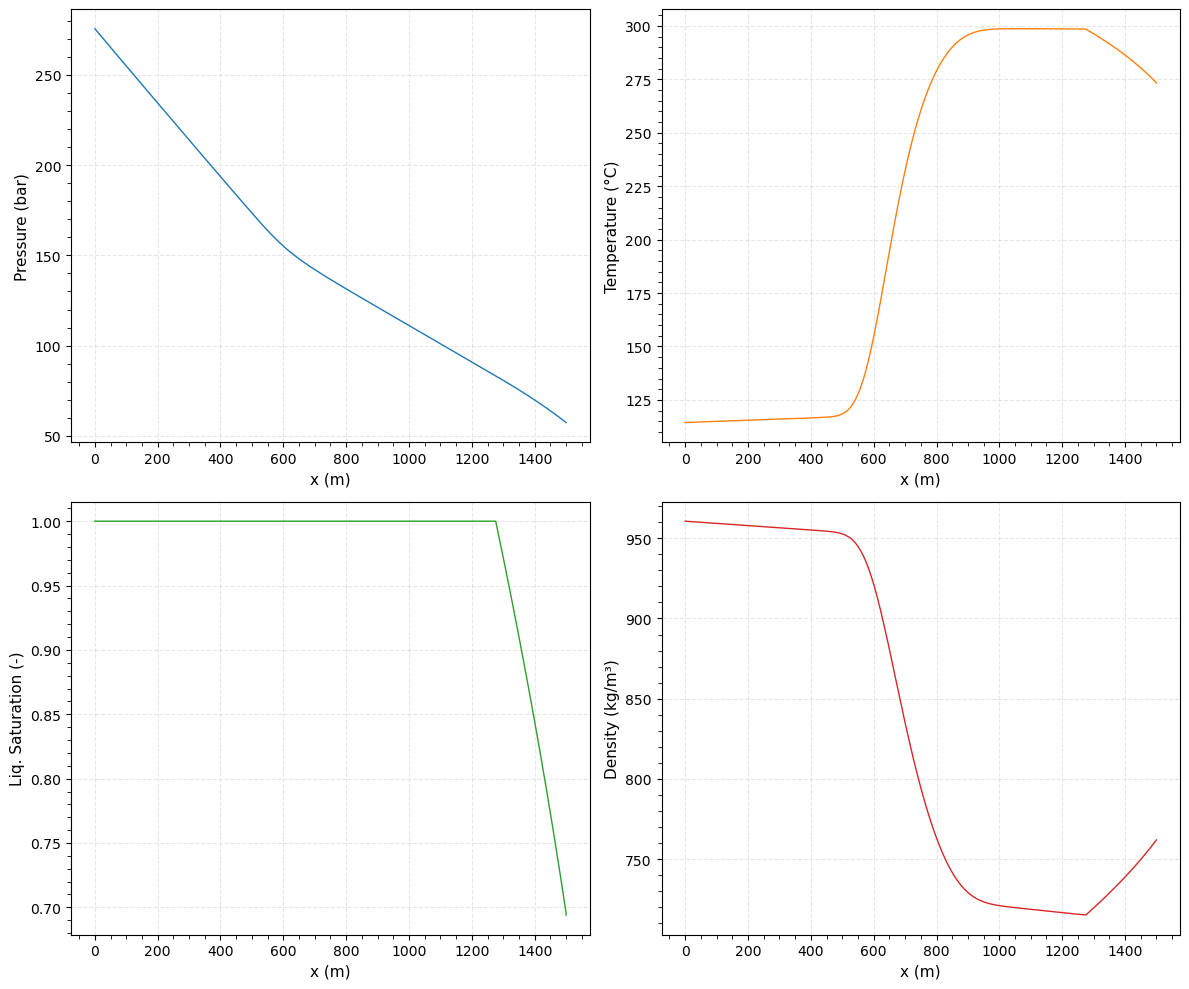

In [107]:
# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

#x-coordinates
xi=[]
for blk in t2geo.blocklist:
    xi.append(blk.centre[0])

# Flatten axes for easier indexing
axes = axes.flatten()

# Define variables to plot and their units
variables = ['P', 'T', 'SW', 'DW']
units = ['Pressure (bar)', 'Temperature (°C)', 'Liq. Saturation (-)', 'Density (kg/m³)']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Colors

# Create plots
for i, (var, unit, color) in enumerate(zip(variables, units, colors)):
    ax = axes[i]
    
    # Plot the data
    if var=='P':
        converf=101.E3
    else:
        converf=1.0
    ax.plot(xi, df[var]/converf, 's-', color=color, markersize=0, linewidth=1.0, 
            markerfacecolor='white', markeredgecolor=color, markeredgewidth=1)
    
    # Customize the plot
    ax.set_xlabel('x (m)', fontsize=11)
    ax.set_ylabel(unit, fontsize=11)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.tick_params(axis='both', which='major', labelsize=10)
    
    # Add minor ticks for better readability
    ax.minorticks_on()
    ax.tick_params(axis='both', which='minor', length=3)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()